# import nessaciary

In [4]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import warnings 
warnings.filterwarnings("ignore")

# import dataset

In [3]:
car_data=pd.read_csv("Cars.csv")
car_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


## step 3 :data understanding

### perform initial performance in data

In [4]:
car_data.isnull().sum()

HP     0
MPG    0
VOL    0
SP     0
WT     0
dtype: int64

In [9]:
car_data.shape

(81, 5)

In [10]:
car_data.describe()

,HP,MPG,VOL,SP,WT
count,81.000000,81.000000,81.000000,81.000000,81.000000
mean,117.469136,34.422076,98.765432,121.540272,32.412577
std,57.113502,9.131445,22.301497,14.181432,7.492813
min,49.000000,12.101263,50.000000,99.564907,15.712859
25%,84.000000,27.856252,89.000000,113.829145,29.591768
50%,100.000000,35.152727,101.000000,118.208698,32.734518
75%,140.000000,39.531633,113.000000,126.404312,37.392524
max,322.000000,53.700681,160.000000,169.598513,52.997752


In [10]:
car_data.dtypes

HP       int64
MPG    float64
VOL      int64
SP     float64
WT     float64
dtype: object

##  now lets check for the assumps linear regression

### test 1:linearity test

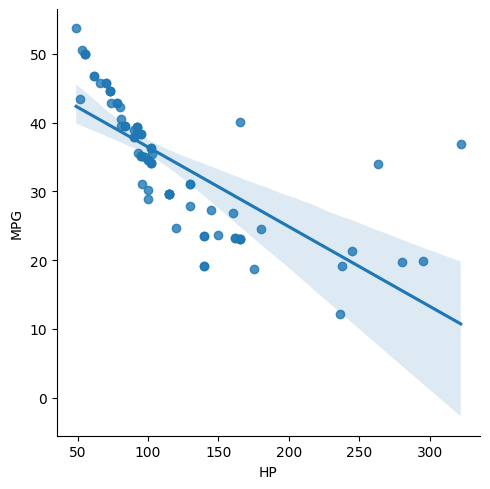

In [11]:
sns.lmplot(data=  car_data,x="HP",y="MPG")
plt.show()

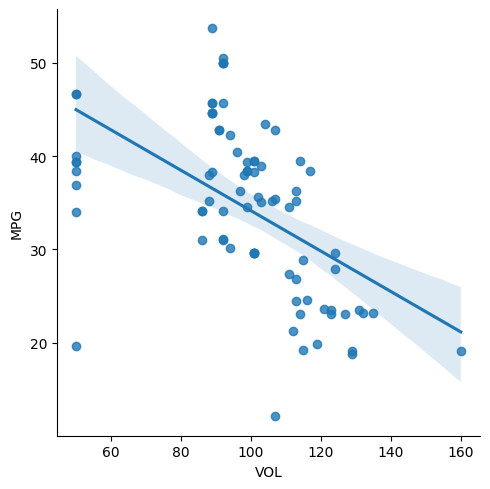

In [12]:
sns.lmplot(data=  car_data,x="VOL",y="MPG")
plt.show()

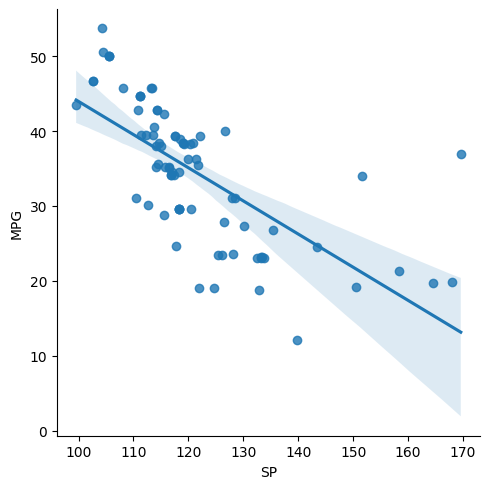

In [13]:
sns.lmplot(data=  car_data,x="SP",y="MPG")
plt.show()

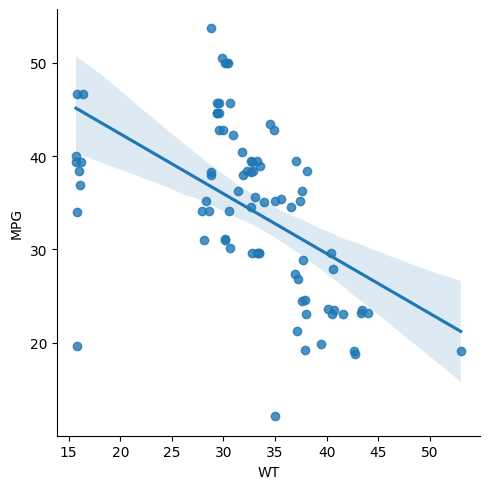

In [14]:
sns.lmplot(data=  car_data,x="WT",y="MPG")
plt.show()

### Test 1:linerity failed

## Test2:Normality test

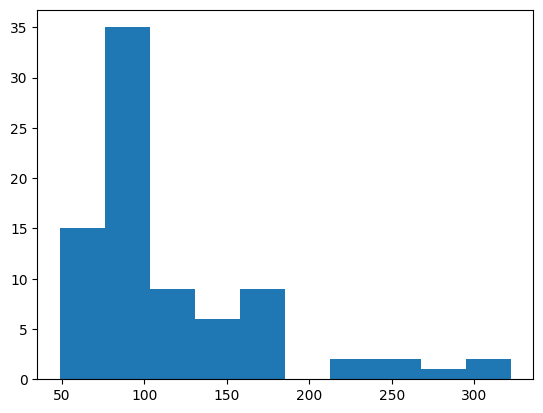

In [15]:
plt.hist(car_data["HP"])
plt.show()

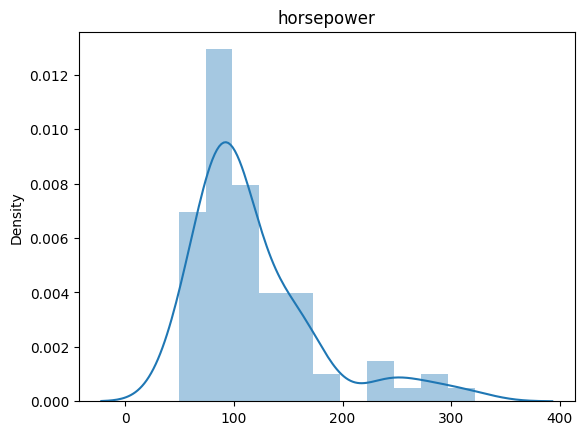

In [16]:
sns.distplot(x=car_data["HP"])
plt.title("horsepower")
plt.show()

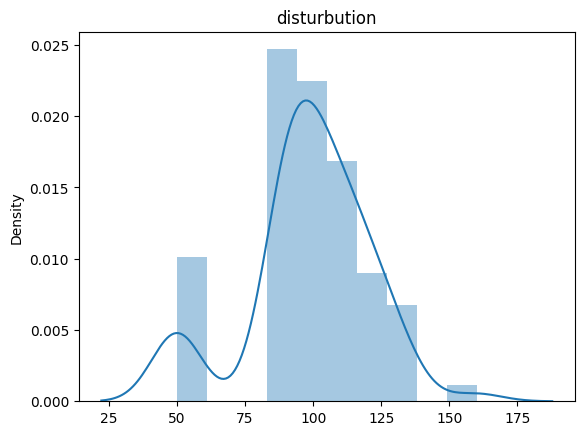

In [17]:
sns.distplot(x=car_data["VOL"])
plt.title("disturbution")
plt.show()

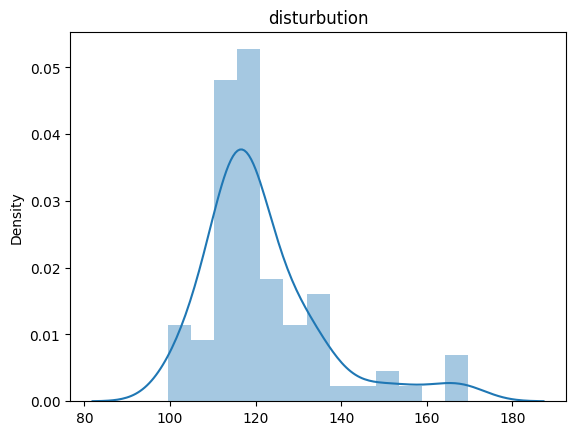

In [18]:
sns.distplot(x=car_data["SP"])
plt.title("disturbution")
plt.show()

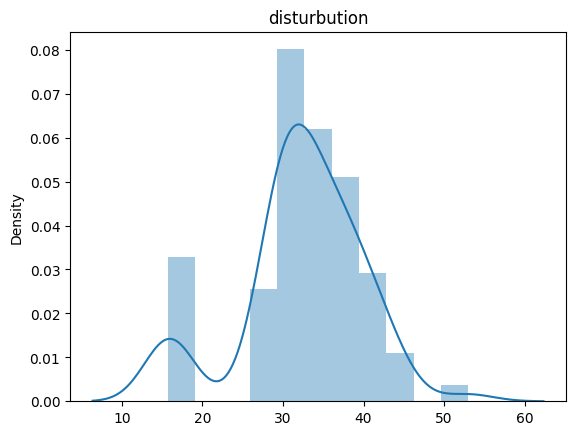

In [19]:
sns.distplot(x=car_data["WT"])
plt.title("disturbution")
plt.show()

### Normality test also failed

## multicollinerity test

In [20]:
corr_matrix=car_data.corr()
corr_matrix

,HP,MPG,VOL,SP,WT
HP,1.000000,-0.725038,0.077459,0.973848,0.076513
MPG,-0.725038,1.000000,-0.529057,-0.687125,-0.526759
VOL,0.077459,-0.529057,1.000000,0.102170,0.999203
SP,0.973848,-0.687125,0.102170,1.000000,0.102439
WT,0.076513,-0.526759,0.999203,0.102439,1.000000


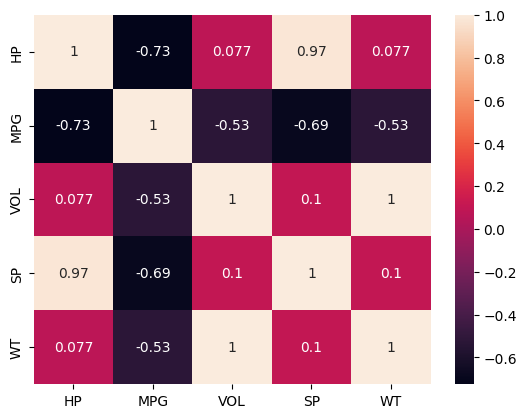

In [21]:
sns.heatmap(data= corr_matrix,annot=True)
plt.show()

### Test3: multi-correllotary is also failed

## Test 4:Auto_regression passed

In [22]:
## time or date or whether no in this data so this is passed

## step 4:Dta preparation

### ther is nothing to prepare because all are numeric.

In [21]:
car_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


In [5]:
X=car_data[["HP","VOL","SP","WT"]]
X

,HP,VOL,SP,WT
0,49,89,104.185353,28.762059
1,55,92,105.461264,30.466833
2,55,92,105.461264,30.193597
3,70,92,113.461264,30.632114
4,53,92,104.461264,29.889149
...,...,...,...,...
76,322,50,169.598513,16.132947
77,238,115,150.576579,37.923113
78,263,50,151.598513,15.769625
79,295,119,167.944460,39.423099


In [6]:
Y= car_data["MPG"]
Y

0     53.700681
1     50.013401
2     50.013401
3     45.696322
4     50.504232
        ...    
76    36.900000
77    19.197888
78    34.000000
79    19.833733
80    12.101263
Name: MPG, Length: 81, dtype: float64

## Data modelling

## model building

In [7]:
 x_train, x_test, y_train, y_test=train_test_split(X,Y,test_size=0.20,shuffle=True,random_state=12)

In [8]:
x_train

,HP,VOL,SP,WT
59,100,115,115.576579,37.662874
63,140,123,125.312342,40.722831
28,52,104,99.564907,34.483207
40,95,113,116.392639,37.392524
43,95,88,114.093383,28.343976
...,...,...,...,...
3,70,92,113.461264,30.632114
2,55,92,105.461264,30.193597
6,55,92,105.461264,30.308480
27,92,99,119.105055,32.835069


In [9]:
linear_model=LinearRegression()

### model training

## data traning test

In [10]:
linear_model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [11]:
linear_model.intercept_

35.243224354290504

In [12]:
linear_model.coef_

array([-0.19037532, -0.46880054,  0.37860499,  0.68495607])

## model testing

In [14]:
y_pred_train = linear_model.predict(x_train)
y_pred_train

array([31.84891407, 26.26544167, 37.90370433, 33.86217856, 38.5138239 ,
       36.30847247, 22.62323268, 28.05889807, 37.18009477, 19.00654776,
       25.76354891, 26.56197102, 23.44572669, 21.77337396, 41.83050633,
       39.38123004, 25.97959426, 38.86711093, 49.60253102, 42.43953488,
       36.62860809, 35.62412115, 42.04599212, 28.4999423 , 35.68327873,
       41.99570757, 40.27270958, 48.6651069 , 13.88294336, 33.9231852 ,
       35.75660232, 30.16637073, 33.68869062, 40.90874672, 36.47557668,
       29.93194311, 38.5521749 , 41.26459975, 33.53611171, 17.10153823,
       41.53420536, 37.24797144, 28.02219808, 34.14665787, 34.54639253,
       39.08471651, 39.74654901, 24.62117109, 37.56930688, 21.46948998,
       43.33742688, 37.00772771, 41.84084566, 43.31530465, 28.47543643,
       33.7035955 , 37.73223515, 37.83186511, 23.38197409, 42.72595522,
       42.25237994, 42.33106975, 38.90178996, 21.05650982])

In [16]:
y_pred_test = linear_model.predict(x_test)
y_pred_test

array([33.20771927, 40.02289413, 42.01631654, 49.69925455, 38.07665913,
       35.2798795 , 50.049764  , 24.3631194 , 35.95220006, 49.90431366,
       34.6709292 , 37.63508988, 17.03568886, 36.86927074, 28.58666317,
       39.72128407, 31.65402822])

## data testing test

In [17]:
linear_model.fit(x_test,y_test)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [18]:
linear_model.intercept_

30.211948290549415

In [27]:
linear_model.coef_

array([-0.22925691,  0.38614753,  0.34007843, -1.51069372])

### model evaluation

ValueError: operands could not be broadcast together with shapes (64,) (17,) 

In [44]:
car_data["error"] = error
car_data

,HP,MPG,VOL,SP,WT,error
0,49,53.700681,89,104.185353,28.762059,10.258747
1,55,50.013401,92,105.461264,30.466833,7.624608
2,55,50.013401,92,105.461264,30.193597,7.734060
3,70,45.696322,92,113.461264,30.632114,3.157963
4,53,50.504232,92,104.461264,29.889149,8.331584
...,...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947,15.617904
77,238,19.197888,115,150.576579,37.923113,1.298838
78,263,34.000000,50,151.598513,15.769625,7.863547
79,295,19.833733,119,167.944460,39.423099,7.517122


In [43]:
del cars_data["error"]

## Let's now perform Test 5: Homoscedasticity Test

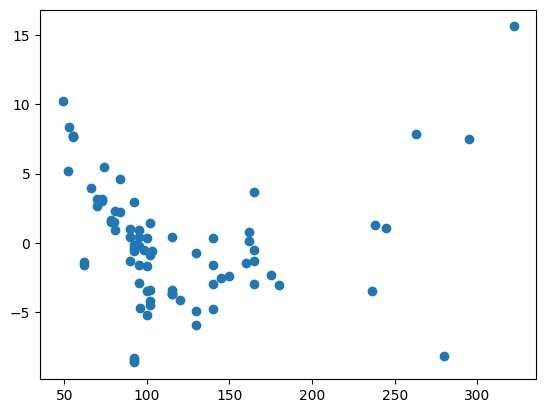

In [46]:
plt.scatter(data=car_data, x = "HP", y = "error")

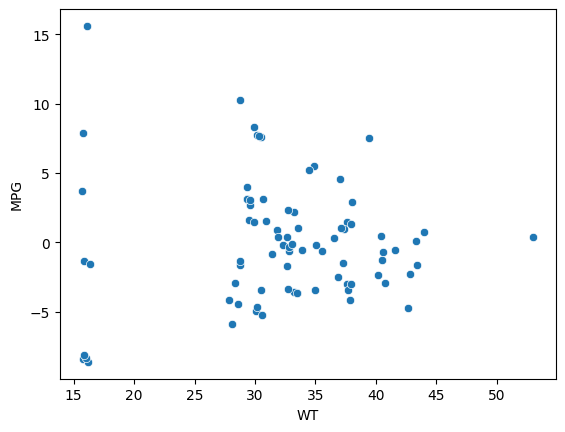

In [48]:
sns.scatterplot( data=car_data,x = "WT", y = error)
plt.show()

###  Test 5 Homoscedasticity Test also Failed

## Test 6: Zero Residual Mean Test

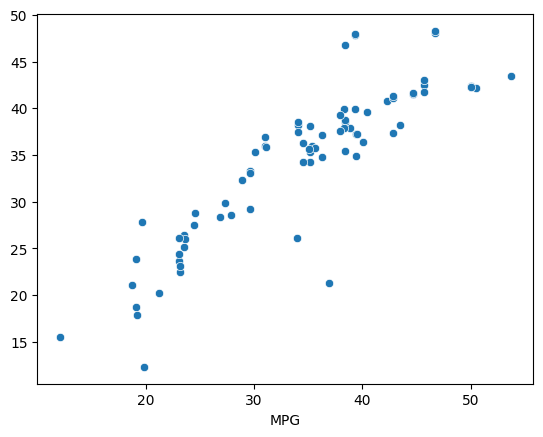

In [50]:
sns.scatterplot(x = car_data["MPG"], y = y_pred)
plt.show()

### Test 6: Zero Residual Mean Test is also Failed

In [51]:
from pickle import dump

In [52]:
dump(obj = linear_model,file = open(file = "linear_intelligence_file.pkl", mode='wb'))

In [53]:
from pickle import load

In [54]:
linear_intel_pkl = load(file = open(file = "linear_intelligence_file.pkl", mode='rb'))
linear_intel_pkl

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [55]:
linear_intel_pkl.predict(X)

array([43.44193477, 42.38879289, 42.27934147, 42.53835981, 42.17264802,
       43.02061916, 42.32536062, 48.07621852, 48.28120247, 40.79122814,
       41.52153227, 47.80956747, 39.95980269, 41.52757889, 41.76632332,
       41.6181448 , 41.15094046, 47.98605515, 41.30861046, 37.87127922,
       38.57706414, 37.35199705, 37.89770285, 39.5625144 , 39.93380662,
       46.73870908, 35.48165898, 38.78152504, 38.24861192, 36.00285298,
       34.84603989, 37.21630246, 37.13919796, 34.82541399, 37.22361389,
       37.53950097, 39.27144845, 38.24219888, 38.54286458, 35.9391722 ,
       34.2129755 , 35.36313259, 37.50473376, 38.07998482, 35.79651664,
       36.2613377 , 34.21826465, 35.59393404, 36.91805291, 33.31108154,
       33.21313413, 33.3023649 , 29.19864884, 27.52358579, 28.3207133 ,
       28.56722621, 35.81583602, 33.02108459, 35.37334971, 32.29909503,
       29.87685849, 28.76093817, 25.14188416, 26.47040896, 25.97651933,
       36.35652478, 26.0975912 , 23.6416178 , 24.39887199, 20.21

# THE END!